# 横磁場イジングモデル：基底エネルギー$E_0$

基底エネルギー$E_0$を、厳密対角化・Jordan-Wigner変換・VQEの3つの手法で求めて比較する。模型の定義は [00_model.ipynb](00_model.ipynb)、各手法のTFIMへの適用は [01_exact_diag](01_exact_diag.ipynb)・[02_jordan_wigner](02_jordan_wigner.ipynb)・[03_trotter](03_trotter.ipynb)・[04_vqe](04_vqe.ipynb)、手法の一般論は [methods/](../../methods/) を参照。

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 厳密対角化（src/qmb/operators.py, ed.py）と TFIM の定義（src/qmb/models.py）
from qmb.operators import plus_state
from qmb.ed import ground_state, time_evolve_expectation
from qmb.models import tfim_hamiltonian as hamiltonian, magnetization_x
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# 各手法の TFIM への適用（src/qmb/models.py, circuits.py）
from qmb.models import tfim_ground_energy_ff as ground_energy_jw, tfim_mx_quench_ff as mx_jw
from qmb.circuits import tfim_op, mx_op, plus_circuit, trotter_step, mx_trotter, vqe
# 実装を見たいときは、Jupyterで関数名の後に ?? を付けて実行する（例: tfim_hamiltonian??）

## 1. 厳密対角化とJordan-Wigner変換の比較

$n=2$から$10$まで、厳密対角化（$2^n\times2^n$行列）とJordan-Wigner変換（$2n\times2n$行列）で$E_0$を求め、差と計算時間を比べる。

 n   E0 (ED)          E0 (JW)          差
 2  -1.720465053409  -1.720465053409  0.0e+00
 3  -2.786586850674  -2.786586850674  1.8e-15
 4  -3.872983346207  -3.872983346207  1.8e-15
 5  -4.971328118240  -4.971328118240  8.9e-16
 6  -6.077639082402  -6.077639082402  3.6e-15
 7  -7.189581641097  -7.189581641097  4.4e-15
 8  -8.305610965881  -8.305610965881  0.0e+00
 9  -9.424632491731  -9.424632491731  1.8e-15
10  -10.545844370449  -10.545844370449  5.3e-15


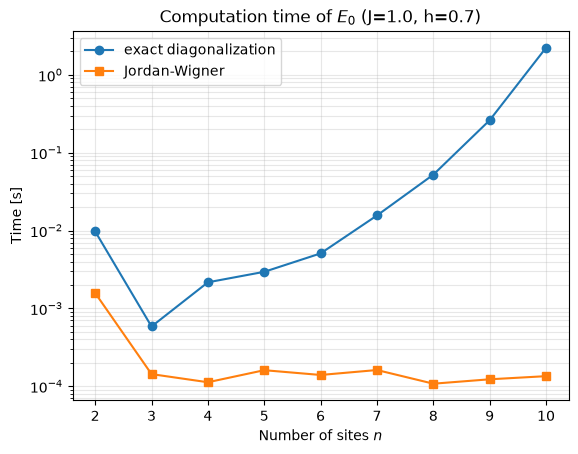

In [3]:
import time

J = 1.0
h = 0.7
ns = range(2, 11)
t_ed, t_jw = [], []
print(" n   E0 (ED)          E0 (JW)          差")
for n in ns:
    start = time.perf_counter()
    E_ed = ground_state(hamiltonian(n, J, h))[0]
    t_ed.append(time.perf_counter() - start)

    start = time.perf_counter()
    E_jw = ground_energy_jw(n, J, h)
    t_jw.append(time.perf_counter() - start)
    print(f"{n:2d}  {E_ed:.12f}  {E_jw:.12f}  {abs(E_ed - E_jw):.1e}")

plt.semilogy(list(ns), t_ed, "o-", label="exact diagonalization")
plt.semilogy(list(ns), t_jw, "s-", label="Jordan-Wigner")
plt.xlabel("Number of sites $n$")
plt.ylabel("Time [s]")
plt.title(f"Computation time of $E_0$ (J={J}, h={h})")
plt.legend()
plt.grid(which="both", alpha=0.3)
plt.show()

2つの手法の$E_0$は数値誤差の範囲（$10^{-12}$程度）で一致している。計算時間は、厳密対角化が$n$とともに指数関数的に増えるのに対し、Jordan-Wigner変換はほとんど増えない。

## 2. 大きな$n$と熱力学極限

Jordan-Wigner変換なら大きな$n$も計算できるので、1サイトあたりのエネルギー$E_0/n$が$n\to\infty$でどこに近づくかを調べる。周期境界条件で波数$k$についてフーリエ変換すると（[02_jordan_wigner.ipynb](02_jordan_wigner.ipynb)の2節の補足）、熱力学極限での値は

\begin{equation}
e_0 = \lim_{n\to\infty}\frac{E_0}{n} = -\frac{1}{2\pi}\int_{-\pi}^{\pi}\sqrt{J^2 + h^2 - 2Jh\cos k}\,dk
\end{equation}

となる。特に$h=J$では$e_0 = -4J/\pi$である。開放境界条件では、両端の分だけ$1/n$に比例するずれが加わる。

h=0.5: e0(∞) = -1.06354441,  E0/n (n=400) = -1.06136773
h=1.0: e0(∞) = -1.27323954,  E0/n (n=400) = -1.27233191
h=2.0: e0(∞) = -2.12708882,  E0/n (n=400) = -2.12675990


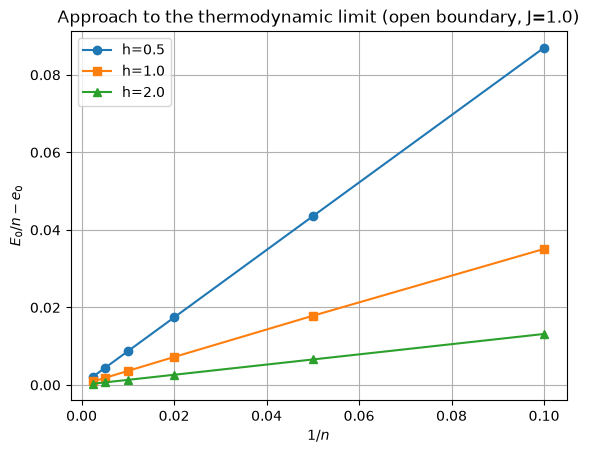

In [4]:
from scipy.integrate import quad

J = 1.0
ns = np.array([10, 20, 50, 100, 200, 400])
for h, mk in [(0.5, "o-"), (1.0, "s-"), (2.0, "^-")]:
    e0_inf = -quad(lambda k: np.sqrt(J**2 + h**2 - 2 * J * h * np.cos(k)), -np.pi, np.pi)[0] / (2 * np.pi)
    e0_n = np.array([ground_energy_jw(n, J, h) / n for n in ns])
    print(f"h={h}: e0(∞) = {e0_inf:.8f},  E0/n (n=400) = {e0_n[-1]:.8f}")
    plt.plot(1 / ns, e0_n - e0_inf, mk, label=f"h={h}")

plt.xlabel("$1/n$")
plt.ylabel(r"$E_0/n - e_0$")
plt.title(f"Approach to the thermodynamic limit (open boundary, J={J})")
plt.legend()
plt.grid()
plt.show()

$E_0/n - e_0$は$1/n$に比例して0に近づく（グラフが原点を通る直線になる）。傾きは開放境界の両端によるエネルギーのずれ（境界エネルギー）を表す。

## 3. VQEとの比較

VQEで$n=6$の$E_0$を求め、層の数$p$を増やしたときの収束を、一様なHVAと局所的なHVAで比べる（2つのHVAの違いは [04_vqe.ipynb](04_vqe.ipynb)の1節を参照）。まず周期境界条件で比べ、次に開放境界条件で比べる。

周期境界条件では、ボンド$(n-1, 0)$を加えた

\begin{equation}
H = -J\sum_{j=0}^{n-1} Z_jZ_{j+1} - h\sum_{j=0}^{n-1} X_j,\quad Z_n \equiv Z_0
\end{equation}

を考え、HVAの$e^{-i\beta H_{ZZ}}$にもボンド$(n-1, 0)$の$R_{ZZ}$ゲートを加える（`vqe(..., pbc=True)`）。厳密な$E_0$は、どちらの境界条件でも厳密対角化で求める（開放境界条件ではJordan-Wigner変換の結果と一致する）。

以下の関数で、一様なHVAと局所的なHVAそれぞれについて、$p=1, \dots, p_{\max}$での相対誤差$|E - E_0|/|E_0|$を計算してグラフにする。

In [4]:
def compare_hva(N, J, h, p_max, pbc):
    # 一様なHVAと局所的なHVAで VQE を行い、相対誤差を表示・プロットする
    E0 = ground_state(hamiltonian(N, J, h, pbc=pbc))[0]
    bc = "periodic" if pbc else "open"
    print(f"E0 (ED, {bc}) = {E0:.10f}")
    ps = np.arange(1, p_max + 1)
    for local, mk, name in [(False, "o-", "uniform HVA"), (True, "s-", "local HVA")]:
        E_vqe, _ = vqe(N, J, h, p_max, local=local, pbc=pbc)
        rel_err = np.abs(E_vqe - E0) / np.abs(E0)
        for p, E, err in zip(ps, E_vqe, rel_err):
            print(f"{name:12s} p={p}: E = {E:.10f}  相対誤差 = {err:.1e}")
        plt.semilogy(ps, np.maximum(rel_err, 1e-16), mk, label=name)
    plt.axvline(N / 2, color="gray", ls=":", label=r"$p = n/2$")
    plt.xticks(ps)
    plt.xlabel("Number of layers $p$")
    plt.ylabel(r"Relative error $|E - E_0| / |E_0|$")
    plt.title(f"VQE convergence ({bc} boundary, N={N}, J={J}, h={h})")
    plt.legend()
    plt.grid(which="both", alpha=0.3)
    plt.show()

### 3.1 周期境界条件

E0 (ED, periodic) = -6.7828160575
uniform HVA  p=1: E = -5.7619666847  相対誤差 = 1.5e-01
uniform HVA  p=2: E = -6.1373686009  相対誤差 = 9.5e-02
uniform HVA  p=3: E = -6.7828160575  相対誤差 = 8.5e-14
uniform HVA  p=4: E = -6.7828160575  相対誤差 = 2.5e-14
local HVA    p=1: E = -5.7619666847  相対誤差 = 1.5e-01
local HVA    p=2: E = -6.1373686006  相対誤差 = 9.5e-02
local HVA    p=3: E = -6.7828160575  相対誤差 = 1.7e-12
local HVA    p=4: E = -6.7828160575  相対誤差 = 5.5e-12


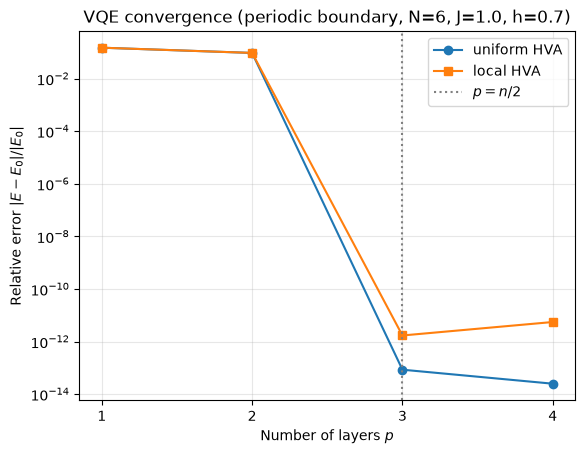

In [5]:
N = 6
J = 1.0
h = 0.7
p_max = 4
compare_hva(N, J, h, p_max, pbc=True)

一様なHVAも局所的なHVAも、$p=3=n/2$層で厳密値に（最適化の精度で）一致する。$p=1, 2$では2つのHVAのエネルギーは同じで、局所的なHVAにしてパラメータを増やしても改善しない。これは、周期境界条件では全サイトが同等（並進対称）なので、サイトごとに角度を変える必要がないからである。一様なHVAが$p=n/2$で厳密値に到達することは、W. W. Ho and T. H. Hsieh, SciPost Phys. 6, 029 (2019) で示されている。

- **なぜ$p=n/2$なのか**

  周期境界条件では並進対称性があるので、Jordan-Wigner変換したあと波数$k$でフーリエ変換すると（[02_jordan_wigner.ipynb](02_jordan_wigner.ipynb)の2節の補足）、$H_{ZZ}$も$H_X$も$(k, -k)$のペアごとの2準位系（擬スピン）の和に分解される。ペアは$n/2$組ある。基底状態は、$n/2$個の擬スピンをそれぞれの$H(k)$の基底状態の向きにそろえた状態である。

  $H_{ZZ}$と$H_X$が同じペアごとに分解されるので、一様なHVAの各層は「$n/2$個の擬スピンを、共通の角度$(\beta_l, \gamma_l)$で、$k$ごとに異なる軸のまわりに回転させる」操作になる。$n/2$個の擬スピンの向き（それぞれ球面上の点で2自由度）をすべて合わせるには、おおまかに数えて$n$個程度のパラメータが必要であり、一様なHVAのパラメータ$2p$個は$p=n/2$でちょうど足りる。

- **光円錐との関係**

  1層の回路は隣のサイトとしか相関を作れないので、$p$層では距離$2p$までしか相関が届かない。リングの上で最も離れたサイトの距離は$n/2$なので、光円錐からは$p \ge n/4$が必要になる。$n=6$では$p \ge 2$であり、実際に必要な$p=3$より小さい。したがって周期境界条件で$p=n/2$層が必要になるのは、相関の届く距離ではなく、上のパラメータの数が理由である。

### 3.2 開放境界条件

E0 (ED, open) = -6.0776390824
uniform HVA  p=1: E = -5.5474120677  相対誤差 = 8.7e-02
uniform HVA  p=2: E = -5.8385839971  相対誤差 = 3.9e-02
uniform HVA  p=3: E = -5.9585924457  相対誤差 = 2.0e-02
uniform HVA  p=4: E = -6.0264931431  相対誤差 = 8.4e-03
local HVA    p=1: E = -5.5779693855  相対誤差 = 8.2e-02
local HVA    p=2: E = -5.9083229015  相対誤差 = 2.8e-02
local HVA    p=3: E = -6.0776382360  相対誤差 = 1.4e-07
local HVA    p=4: E = -6.0776382341  相対誤差 = 1.4e-07


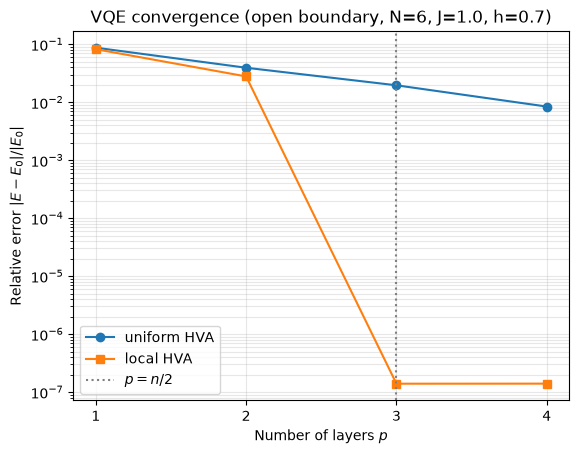

In [6]:
N = 6
J = 1.0
h = 0.7
p_max = 4
compare_hva(N, J, h, p_max, pbc=False)

局所的なHVAは$p=3=n/2$層で一気に厳密値（相対誤差は最適化の精度程度）に到達するが、一様なHVAは$p$を増やしてもゆっくりとしか近づかない。

- **局所的なHVAが$p=3$で到達する理由（光円錐）**

  開放境界条件では、鎖の両端（距離$n-1$）の間にも相関が必要なので、光円錐から$2p \ge n-1$、すなわち$p \ge (n-1)/2$層が必要になる。$n=6$では$p \ge 3$である。局所的なHVAはこの下限の$p=3$で厳密値に到達している。この条件は一様なHVAにも同じように当てはまる必要条件であり、一様なHVAが届かない理由にはならない。

- **一様なHVAの収束が遅い理由（端の効果）**

  開放境界条件では端があるので並進対称性がなく、周期境界条件のように$H_{ZZ}$（ボンド$n-1$本）と$H_X$（サイト$n$個）を同じ独立な2準位系に分解できない。また、端のスピンは隣が1つしかないので、基底状態での$\langle X_j\rangle$や$\langle Z_jZ_{j+1}\rangle$は端と中央で異なる。一様なHVAは全サイトに同じ角度を使うので、この違いを調整できない。一様なHVAの出力状態もサイトごとに少し異なるが、その違いは「端にゲートがない」という回路の形で決まっていて、パラメータで調整できない。局所的なHVAはゲートごとに角度を変えられるので、端の効果を表現できる。

したがって、開放境界条件で一様なHVAが厳密値になかなか届かないのは、層の数が足りないからではなく、アンザッツが端の効果を表現できないからである。周期境界条件の結果（端がなければ一様なHVAでも$p=n/2$で届く）が、このことを裏付けている。

## まとめ

- 厳密対角化とJordan-Wigner変換の$E_0$は数値誤差の範囲で一致する。Jordan-Wigner変換なら$n=400$でも一瞬で計算でき、熱力学極限の値も確かめられる。
- 周期境界条件では、一様なHVAも局所的なHVAも$p=n/2$層で厳密値に到達する。並進対称性によって$n/2$個の擬スピンに分解でき、それらを合わせるのに必要なパラメータの数から$p=n/2$が決まる。
- 開放境界条件では、局所的なHVAは光円錐の下限$p=n/2$（$n$が偶数のとき）で厳密値に到達するが、一様なHVAは端の効果を表現できないため収束が遅い。